In [1]:
import torch
print("torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

torch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [2]:
!git clone https://github.com/neuronautsai/ldct-iqac-resnet18.git
%cd ldct-iqac-resnet18
!git checkout 90afae67d1fea3ac10edecd43fde0360cf3fb4f1
!git log -1 --format=%H
!pip install -q imageio pandas matplotlib scipy scikit-learn tqdm

Cloning into 'ldct-iqac-resnet18'...
remote: Enumerating objects: 23, done.
remote: Counting objects: 100% (23/23), done.
remote: Compressing objects: 100% (22/22), done.
remote: Total 23 (delta 1), reused 19 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (23/23), 336.65 KiB | 1.78 MiB/s, done.
Resolving deltas: 100% (1/1), done.
/content/ldct-iqac-resnet18
Note: switching to '90afae67d1fea3ac10edecd43fde0360cf3fb4f1'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

HEAD is now at 90afae6 Add ResNet18 baseline for 

In [3]:
import os, glob, zipfile

ZIP_PATH = "/content/LDCTIQAG2023_train.zip"
EXTRACT_DIR = "/content/ldct_data"

with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall(EXTRACT_DIR)

# train.json dosyasını bul, klasörü DATA_DIR yap
matches = glob.glob(f"{EXTRACT_DIR}/**/train.json", recursive=True)
print("train.json bulunan yerler:", matches)

DATA_DIR = os.path.dirname(matches[0])
print("DATA_DIR:", DATA_DIR)
print("train.json var mı:", os.path.exists(f"{DATA_DIR}/train.json"))
print("image klasörü var mı:", os.path.isdir(f"{DATA_DIR}/image"))
print("Görüntü sayısı:", len(glob.glob(f"{DATA_DIR}/image/*.tif")))

train.json bulunan yerler: ['/content/ldct_data/LDCTIQAG2023_train/train.json']
DATA_DIR: /content/ldct_data/LDCTIQAG2023_train
train.json var mı: True
image klasörü var mı: True
Görüntü sayısı: 1000


In [4]:
from pathlib import Path
from config import Config
from data import load_master_list, split_master_list
from utils import set_seed

config = Config(data_dir=Path(DATA_DIR))
set_seed(config.seed)

df = load_master_list(config.data_dir)
train_df, val_df, test_df = split_master_list(df, config.seed)

print("Toplam:", len(df))
print("Train / Val / Test:", len(train_df), len(val_df), len(test_df))

assert not (set(train_df.Filename) & set(val_df.Filename))
assert not (set(train_df.Filename) & set(test_df.Filename))
assert not (set(val_df.Filename) & set(test_df.Filename))
print("Çakışma yok.")
print("MOS aralığı:", df["MOS Score"].min(), "-", df["MOS Score"].max())

Toplam: 1000
Train / Val / Test: 800 100 100
Çakışma yok.
MOS aralığı: 0.0 - 4.0


In [5]:
import torch
import torch.nn as nn

mse_loss = nn.MSELoss()
mae_loss = nn.L1Loss()
huber_loss = nn.SmoothL1Loss(beta=1.0)

def pairwise_ranking_loss(preds, labels, margin=0.1):
    n = preds.size(0)
    pred_diff = preds.unsqueeze(1) - preds.unsqueeze(0)
    label_diff = labels.unsqueeze(1) - labels.unsqueeze(0)
    target = torch.sign(label_diff)
    loss = torch.clamp(margin - target * pred_diff, min=0)
    mask = torch.triu(torch.ones(n, n), diagonal=1).bool().to(preds.device)
    return loss[mask].mean()

def combined_loss(preds, labels):
    return 0.5 * mse_loss(preds, labels) + 0.5 * pairwise_ranking_loss(preds, labels)

LOSSES = {
    "mse": mse_loss,
    "mae": mae_loss,
    "huber": huber_loss,
    "ranking": pairwise_ranking_loss,
    "combined": combined_loss,
}
print("Kayıplar:", list(LOSSES))

Kayıplar: ['mse', 'mae', 'huber', 'ranking', 'combined']


In [6]:
import copy
import json
import numpy as np
import torch
from pathlib import Path
from data import make_loaders
from model import create_model
from train import train_one_epoch, evaluate, DEVICE
from utils import set_seed, compute_metrics

OUT_DIR = Path("/content/outputs_b")
OUT_DIR.mkdir(exist_ok=True)

@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds, targets = [], []
    for imgs, labels in loader:
        preds.append(model(imgs.to(DEVICE)).squeeze(1).cpu().numpy())
        targets.append(labels.numpy())
    return np.concatenate(preds), np.concatenate(targets)

def run_experiment(loss_name, num_epochs=config.num_epochs):
    loss_fn = LOSSES[loss_name]

    set_seed(config.seed)
    train_loader, val_loader, test_loader = make_loaders(train_df, val_df, test_df, config)
    set_seed(config.seed)
    model = create_model().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate)

    history = {"train_loss": [], "val_loss": [], "val_mse": [], "val_srocc": []}
    best_val, best_epoch, best_state = float("inf"), 0, None

    for epoch in range(1, num_epochs + 1):
        train_loss = train_one_epoch(model, train_loader, optimizer, loss_fn)
        val_loss, val_srocc = evaluate(model, val_loader, loss_fn)
        val_mse, _ = evaluate(model, val_loader, mse_loss)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_mse"].append(val_mse)
        history["val_srocc"].append(val_srocc)

        if val_loss < best_val:
            best_val, best_epoch = val_loss, epoch
            best_state = copy.deepcopy(model.state_dict())

        flag = " * best" if epoch == best_epoch else ""
        print(f"[{loss_name}] Epoch {epoch:02d}/{num_epochs} | train {train_loss:.4f} | "
              f"val {val_loss:.4f} | val MSE {val_mse:.4f} | val SROCC {val_srocc:.4f}{flag}")

    model.load_state_dict(best_state)
    torch.save(best_state, OUT_DIR / f"b1_{loss_name}.pth")
    preds, targets = predict(model, test_loader)
    metrics = compute_metrics(preds, targets)

    result = {"loss": loss_name, "best_epoch": best_epoch, "best_val_loss": best_val,
              "history": history, "test_metrics": metrics}
    with open(OUT_DIR / f"b1_{loss_name}.json", "w") as f:
        json.dump(result, f)
    print(f"[{loss_name}] best epoch {best_epoch}, test metrics: {metrics}")
    return result

In [7]:
import time
t0 = time.time()
smoke = run_experiment("mse", num_epochs=1)
print(f"Süre: {time.time() - t0:.1f} sn")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 179MB/s]


[mse] Epoch 01/1 | train 1.0985 | val 0.4085 | val MSE 0.4085 | val SROCC 0.9005 * best
[mse] best epoch 1, test metrics: {'N': 100, 'MAE': 0.5465730428695679, 'RMSE': 0.6390551924705505, 'PLCC': 0.8792402744293213, 'SROCC': 0.873757879758032, 'KROCC': 0.716226402717039}
Süre: 18.4 sn


In [8]:
results = {}
results["mse"] = run_experiment("mse")

[mse] Epoch 01/50 | train 1.0985 | val 0.4085 | val MSE 0.4085 | val SROCC 0.9005 * best


[mse] Epoch 02/50 | train 0.1617 | val 0.0729 | val MSE 0.0729 | val SROCC 0.9680 * best


[mse] Epoch 03/50 | train 0.1036 | val 0.1142 | val MSE 0.1142 | val SROCC 0.9666


[mse] Epoch 04/50 | train 0.0980 | val 0.2461 | val MSE 0.2461 | val SROCC 0.9708


[mse] Epoch 05/50 | train 0.1129 | val 0.0847 | val MSE 0.0847 | val SROCC 0.9676


...

[mse] Epoch 46/50 | train 0.0152 | val 0.0998 | val MSE 0.0998 | val SROCC 0.9762


[mse] Epoch 47/50 | train 0.0182 | val 0.0599 | val MSE 0.0599 | val SROCC 0.9748


[mse] Epoch 48/50 | train 0.0180 | val 0.0544 | val MSE 0.0544 | val SROCC 0.9760


[mse] Epoch 49/50 | train 0.0267 | val 0.0694 | val MSE 0.0694 | val SROCC 0.9765


[mse] Epoch 50/50 | train 0.0228 | val 0.0685 | val MSE 0.0685 | val SROCC 0.9729
[mse] best epoch 19, test metrics: {'N': 100, 'MAE': 0.19316619634628296, 'RMSE': 0.2462836056947708, 'PLCC': 0.972374439239502, 'SROCC': 0.9681177663901267, 'KROCC': 0.868800247116385}


In [9]:
results["mae"] = run_experiment("mae")

[mae] Epoch 01/50 | train 0.7125 | val 0.5868 | val MSE 0.4631 | val SROCC 0.8940 * best


[mae] Epoch 02/50 | train 0.3501 | val 0.2831 | val MSE 0.1215 | val SROCC 0.9588 * best


[mae] Epoch 03/50 | train 0.2995 | val 0.2707 | val MSE 0.1094 | val SROCC 0.9592 * best


[mae] Epoch 04/50 | train 0.3206 | val 0.2808 | val MSE 0.1200 | val SROCC 0.9540


[mae] Epoch 05/50 | train 0.2949 | val 0.4015 | val MSE 0.2418 | val SROCC 0.9454


...

[mae] Epoch 46/50 | train 0.1124 | val 0.1907 | val MSE 0.0635 | val SROCC 0.9733


[mae] Epoch 47/50 | train 0.0931 | val 0.1942 | val MSE 0.0564 | val SROCC 0.9744


[mae] Epoch 48/50 | train 0.1016 | val 0.1860 | val MSE 0.0589 | val SROCC 0.9731 * best


[mae] Epoch 49/50 | train 0.1350 | val 0.2003 | val MSE 0.0620 | val SROCC 0.9715


[mae] Epoch 50/50 | train 0.0985 | val 0.2041 | val MSE 0.0638 | val SROCC 0.9738
[mae] best epoch 48, test metrics: {'N': 100, 'MAE': 0.19835931062698364, 'RMSE': 0.2548494338989258, 'PLCC': 0.972895085811615, 'SROCC': 0.9689835637442126, 'KROCC': 0.8750192896870105}


In [10]:
     print(test_df["Filename"].head(5).tolist())

['0436.tif', '0899.tif', '0346.tif', '0060.tif', '0867.tif']


In [11]:
results["huber"] = run_experiment("huber")

[huber] Epoch 01/50 | train 0.3576 | val 0.2090 | val MSE 0.4234 | val SROCC 0.9291 * best


[huber] Epoch 02/50 | train 0.0832 | val 0.0337 | val MSE 0.0674 | val SROCC 0.9683 * best


[huber] Epoch 03/50 | train 0.0561 | val 0.0986 | val MSE 0.1974 | val SROCC 0.9679


[huber] Epoch 04/50 | train 0.0522 | val 0.1368 | val MSE 0.2741 | val SROCC 0.9716


[huber] Epoch 05/50 | train 0.0620 | val 0.0750 | val MSE 0.1501 | val SROCC 0.9735


...

[huber] Epoch 46/50 | train 0.0058 | val 0.0424 | val MSE 0.0847 | val SROCC 0.9775


[huber] Epoch 47/50 | train 0.0068 | val 0.0300 | val MSE 0.0600 | val SROCC 0.9749


[huber] Epoch 48/50 | train 0.0061 | val 0.0258 | val MSE 0.0517 | val SROCC 0.9776


[huber] Epoch 49/50 | train 0.0087 | val 0.0489 | val MSE 0.0978 | val SROCC 0.9778


[huber] Epoch 50/50 | train 0.0089 | val 0.0275 | val MSE 0.0549 | val SROCC 0.9752
[huber] best epoch 43, test metrics: {'N': 100, 'MAE': 0.18870680034160614, 'RMSE': 0.2327992469072342, 'PLCC': 0.975648045539856, 'SROCC': 0.9702942847385924, 'KROCC': 0.8737754811728854}


In [12]:
print(test_df["Filename"].head(5).tolist())

['0436.tif', '0899.tif', '0346.tif', '0060.tif', '0867.tif']


In [13]:
results["ranking"] = run_experiment("ranking")

[ranking] Epoch 01/50 | train 0.0438 | val 0.0345 | val MSE 4.4943 | val SROCC 0.9272 * best


[ranking] Epoch 02/50 | train 0.0293 | val 0.0264 | val MSE 5.2457 | val SROCC 0.9536 * best


[ranking] Epoch 03/50 | train 0.0215 | val 0.0277 | val MSE 5.7073 | val SROCC 0.9548


[ranking] Epoch 04/50 | train 0.0176 | val 0.0190 | val MSE 5.6495 | val SROCC 0.9698 * best


[ranking] Epoch 05/50 | train 0.0166 | val 0.0220 | val MSE 4.3601 | val SROCC 0.9667


...

[ranking] Epoch 46/50 | train 0.0083 | val 0.0224 | val MSE 5.1698 | val SROCC 0.9703


[ranking] Epoch 47/50 | train 0.0072 | val 0.0222 | val MSE 3.8508 | val SROCC 0.9740


[ranking] Epoch 48/50 | train 0.0080 | val 0.0206 | val MSE 4.5730 | val SROCC 0.9713


[ranking] Epoch 49/50 | train 0.0071 | val 0.0227 | val MSE 4.0852 | val SROCC 0.9769


[ranking] Epoch 50/50 | train 0.0072 | val 0.0218 | val MSE 3.8730 | val SROCC 0.9770
[ranking] best epoch 14, test metrics: {'N': 100, 'MAE': 2.1487152576446533, 'RMSE': 2.169484853744507, 'PLCC': 0.9669712781906128, 'SROCC': 0.9713705189495739, 'KROCC': 0.8712878641446352}


In [14]:
results["combined"] = run_experiment("combined")

[combined] Epoch 01/50 | train 0.5902 | val 0.2000 | val MSE 0.3633 | val SROCC 0.8998 * best


[combined] Epoch 02/50 | train 0.0918 | val 0.0606 | val MSE 0.0953 | val SROCC 0.9666 * best


[combined] Epoch 03/50 | train 0.0579 | val 0.0578 | val MSE 0.0945 | val SROCC 0.9667 * best


[combined] Epoch 04/50 | train 0.0540 | val 0.1317 | val MSE 0.2426 | val SROCC 0.9660


[combined] Epoch 05/50 | train 0.0627 | val 0.0483 | val MSE 0.0751 | val SROCC 0.9720 * best


...

[combined] Epoch 46/50 | train 0.0101 | val 0.0583 | val MSE 0.0990 | val SROCC 0.9795


[combined] Epoch 47/50 | train 0.0096 | val 0.0372 | val MSE 0.0545 | val SROCC 0.9739


[combined] Epoch 48/50 | train 0.0102 | val 0.0512 | val MSE 0.0841 | val SROCC 0.9740


[combined] Epoch 49/50 | train 0.0124 | val 0.0419 | val MSE 0.0648 | val SROCC 0.9756


[combined] Epoch 50/50 | train 0.0094 | val 0.0386 | val MSE 0.0578 | val SROCC 0.9734
[combined] best epoch 19, test metrics: {'N': 100, 'MAE': 0.1915660798549652, 'RMSE': 0.24277706444263458, 'PLCC': 0.9728335738182068, 'SROCC': 0.9683582656551506, 'KROCC': 0.8700440556305101}


In [15]:
import json
import pandas as pd

rows = []
for name in ["mse", "mae", "huber", "ranking", "combined"]:
    with open(OUT_DIR / f"b1_{name}.json") as f:
        r = json.load(f)
    m = r["test_metrics"]
    rows.append({"Loss": name, "Best epoch": r["best_epoch"], "MAE": m["MAE"],
                 "RMSE": m["RMSE"], "PLCC": m["PLCC"], "SROCC": m["SROCC"], "KROCC": m["KROCC"]})

b1_table = pd.DataFrame(rows).set_index("Loss").round(4)
display(b1_table)
b1_table.to_csv(OUT_DIR / "b1_table.csv")
print("En yüksek SROCC:", b1_table["SROCC"].idxmax(), "| En yüksek KROCC:", b1_table["KROCC"].idxmax())

,Best epoch,MAE,RMSE,PLCC,SROCC,KROCC
Loss,,,,,,
mse,19,0.1932,0.2463,0.9724,0.9681,0.8688
mae,48,0.1984,0.2548,0.9729,0.9690,0.8750
huber,43,0.1887,0.2328,0.9756,0.9703,0.8738
ranking,14,2.1487,2.1695,0.9670,0.9714,0.8713
combined,19,0.1916,0.2428,0.9728,0.9684,0.8700


En yüksek SROCC: ranking | En yüksek KROCC: mae


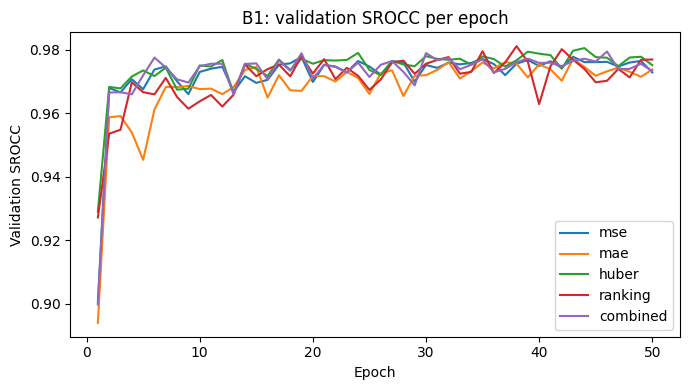

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
for name in ["mse", "mae", "huber", "ranking", "combined"]:
    with open(OUT_DIR / f"b1_{name}.json") as f:
        h = json.load(f)["history"]
    ax.plot(range(1, len(h["val_srocc"]) + 1), h["val_srocc"], label=name)
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation SROCC")
ax.set_title("B1: validation SROCC per epoch")
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "b1_val_srocc.png", dpi=200)
plt.show()

In [17]:
from torch.optim.lr_scheduler import StepLR, CosineAnnealingLR, OneCycleLR

def make_scheduler(name, optimizer, steps_per_epoch, num_epochs):
    if name == "step":
        return StepLR(optimizer, step_size=10, gamma=0.1)
    if name == "cosine":
        return CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-6)
    if name == "onecycle":
        return OneCycleLR(optimizer, max_lr=1e-3, total_steps=steps_per_epoch * num_epochs)
    raise ValueError(name)

def train_epoch_sched(model, loader, optimizer, loss_fn, scheduler=None, step_per_batch=False):
    model.train()
    total = 0.0
    for imgs, labels in loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        loss = loss_fn(model(imgs).squeeze(1), labels)
        loss.backward()
        optimizer.step()
        if step_per_batch:
            scheduler.step()
        total += loss.item() * imgs.size(0)
    return total / len(loader.dataset)

def run_scheduler_experiment(sched_name, loss_name="mse", num_epochs=config.num_epochs):
    loss_fn = LOSSES[loss_name]

    set_seed(config.seed)
    train_loader, val_loader, test_loader = make_loaders(train_df, val_df, test_df, config)
    set_seed(config.seed)
    model = create_model().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate)
    scheduler = make_scheduler(sched_name, optimizer, len(train_loader), num_epochs)
    per_batch = sched_name == "onecycle"

    history = {"lr": [], "train_loss": [], "val_loss": [], "val_mse": [], "val_srocc": []}
    best_val, best_epoch, best_state = float("inf"), 0, None

    for epoch in range(1, num_epochs + 1):
        lr_now = optimizer.param_groups[0]["lr"]
        train_loss = train_epoch_sched(model, train_loader, optimizer, loss_fn, scheduler, per_batch)
        if not per_batch:
            scheduler.step()
        val_loss, val_srocc = evaluate(model, val_loader, loss_fn)
        val_mse, _ = evaluate(model, val_loader, mse_loss)
        history["lr"].append(lr_now)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_mse"].append(val_mse)
        history["val_srocc"].append(val_srocc)

        if val_loss < best_val:
            best_val, best_epoch = val_loss, epoch
            best_state = copy.deepcopy(model.state_dict())

        flag = " * best" if epoch == best_epoch else ""
        print(f"[{sched_name}] Epoch {epoch:02d}/{num_epochs} | lr {lr_now:.2e} | train {train_loss:.4f} | "
              f"val {val_loss:.4f} | val SROCC {val_srocc:.4f}{flag}")

    model.load_state_dict(best_state)
    torch.save(best_state, OUT_DIR / f"b2_{sched_name}.pth")
    preds, targets = predict(model, test_loader)
    metrics = compute_metrics(preds, targets)

    result = {"scheduler": sched_name, "loss": loss_name, "best_epoch": best_epoch,
              "best_val_loss": best_val, "history": history, "test_metrics": metrics}
    with open(OUT_DIR / f"b2_{sched_name}.json", "w") as f:
        json.dump(result, f)
    print(f"[{sched_name}] best epoch {best_epoch}, test metrics: {metrics}")
    return result

In [18]:
smoke = run_scheduler_experiment("onecycle", num_epochs=1)

[onecycle] Epoch 01/1 | lr 4.00e-05 | train 0.9776 | val 0.6821 | val SROCC 0.8885 * best
[onecycle] best epoch 1, test metrics: {'N': 100, 'MAE': 0.6961794495582581, 'RMSE': 0.8212906122207642, 'PLCC': 0.9004648327827454, 'SROCC': 0.8869071770732092, 'KROCC': 0.7336397219147904}


In [19]:
results_b2 = {}
results_b2["step"] = run_scheduler_experiment("step")

[step] Epoch 01/50 | lr 1.00e-04 | train 1.0985 | val 0.4085 | val SROCC 0.9005 * best
[step] Epoch 02/50 | lr 1.00e-04 | train 0.1617 | val 0.0729 | val SROCC 0.9680 * best
[step] Epoch 03/50 | lr 1.00e-04 | train 0.1036 | val 0.1142 | val SROCC 0.9666
[step] Epoch 04/50 | lr 1.00e-04 | train 0.0980 | val 0.2461 | val SROCC 0.9708
[step] Epoch 05/50 | lr 1.00e-04 | train 0.1129 | val 0.0847 | val SROCC 0.9676
[step] Epoch 06/50 | lr 1.00e-04 | train 0.0772 | val 0.0670 | val SROCC 0.9738 * best
[step] Epoch 07/50 | lr 1.00e-04 | train 0.0527 | val 0.0634 | val SROCC 0.9748 * best
[step] Epoch 08/50 | lr 1.00e-04 | train 0.0927 | val 0.0808 | val SROCC 0.9701
[step] Epoch 09/50 | lr 1.00e-04 | train 0.0556 | val 0.1009 | val SROCC 0.9661
[step] Epoch 10/50 | lr 1.00e-04 | train 0.0587 | val 0.0661 | val SROCC 0.9730
[step] Epoch 11/50 | lr 1.00e-05 | train 0.0417 | val 0.0623 | val SROCC 0.9758 * best
[step] Epoch 12/50 | lr 1.00e-05 | train 0.0243 | val 0.0618 | val SROCC 0.9759 * bes

In [20]:
results_b2["cosine"] = run_scheduler_experiment("cosine")

[cosine] Epoch 01/50 | lr 1.00e-04 | train 1.0985 | val 0.4085 | val SROCC 0.9005 * best
[cosine] Epoch 02/50 | lr 9.99e-05 | train 0.1617 | val 0.0727 | val SROCC 0.9679 * best
[cosine] Epoch 03/50 | lr 9.96e-05 | train 0.1034 | val 0.1100 | val SROCC 0.9678
[cosine] Epoch 04/50 | lr 9.91e-05 | train 0.0972 | val 0.2522 | val SROCC 0.9700
[cosine] Epoch 05/50 | lr 9.84e-05 | train 0.1125 | val 0.0894 | val SROCC 0.9673
[cosine] Epoch 06/50 | lr 9.76e-05 | train 0.0771 | val 0.0611 | val SROCC 0.9762 * best
[cosine] Epoch 07/50 | lr 9.65e-05 | train 0.0515 | val 0.0655 | val SROCC 0.9740
[cosine] Epoch 08/50 | lr 9.53e-05 | train 0.0896 | val 0.0786 | val SROCC 0.9719
[cosine] Epoch 09/50 | lr 9.39e-05 | train 0.0517 | val 0.0865 | val SROCC 0.9693
[cosine] Epoch 10/50 | lr 9.23e-05 | train 0.0535 | val 0.0644 | val SROCC 0.9738
[cosine] Epoch 11/50 | lr 9.05e-05 | train 0.0478 | val 0.0842 | val SROCC 0.9745
[cosine] Epoch 12/50 | lr 8.86e-05 | train 0.0271 | val 0.0645 | val SROCC 0.

In [21]:
results_b2["onecycle"] = run_scheduler_experiment("onecycle")

[onecycle] Epoch 01/50 | lr 4.00e-05 | train 1.9773 | val 0.5819 | val SROCC 0.9270 * best
[onecycle] Epoch 02/50 | lr 5.05e-05 | train 0.1880 | val 0.1197 | val SROCC 0.9670 * best
[onecycle] Epoch 03/50 | lr 8.16e-05 | train 0.1064 | val 0.1600 | val SROCC 0.9682
[onecycle] Epoch 04/50 | lr 1.32e-04 | train 0.1112 | val 0.1989 | val SROCC 0.9708
[onecycle] Epoch 05/50 | lr 1.99e-04 | train 0.1749 | val 0.0852 | val SROCC 0.9614 * best
[onecycle] Epoch 06/50 | lr 2.81e-04 | train 0.1463 | val 0.2352 | val SROCC 0.9543
[onecycle] Epoch 07/50 | lr 3.72e-04 | train 0.1231 | val 0.1020 | val SROCC 0.9592
[onecycle] Epoch 08/50 | lr 4.71e-04 | train 0.1945 | val 0.1259 | val SROCC 0.9585
[onecycle] Epoch 09/50 | lr 5.71e-04 | train 0.1656 | val 0.2426 | val SROCC 0.9625
[onecycle] Epoch 10/50 | lr 6.69e-04 | train 0.1574 | val 0.0861 | val SROCC 0.9651
[onecycle] Epoch 11/50 | lr 7.61e-04 | train 0.1410 | val 0.1905 | val SROCC 0.9616
[onecycle] Epoch 12/50 | lr 8.42e-04 | train 0.1201 | v

           Yöntem  Best epoch    MAE   RMSE   PLCC  SROCC  KROCC
Sabit lr (B1 MSE)          19 0.1932 0.2463 0.9724 0.9681 0.8688
           StepLR          47 0.1876 0.2352 0.9749 0.9709 0.8754
CosineAnnealingLR          24 0.1890 0.2372 0.9742 0.9682 0.8700
       OneCycleLR          39 0.1867 0.2363 0.9751 0.9713 0.8779


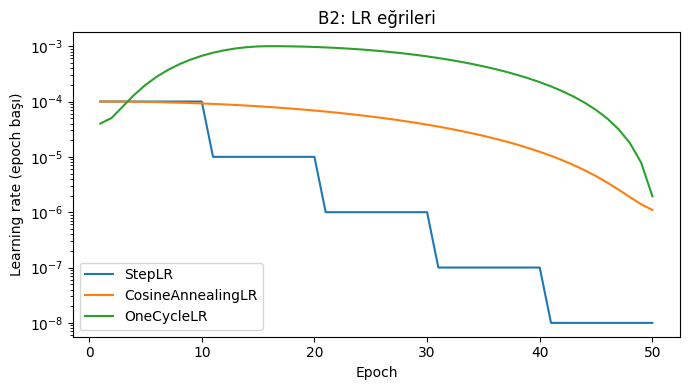

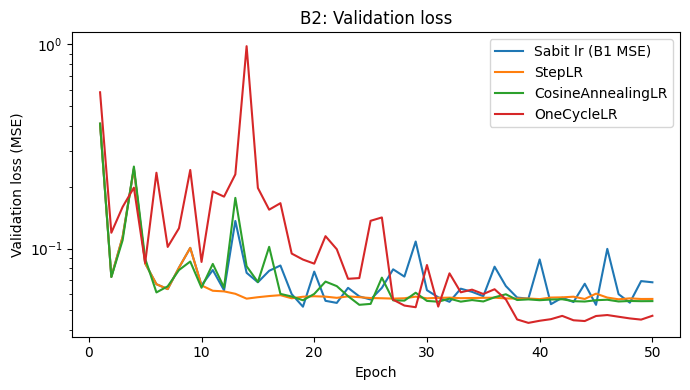

In [22]:
import json
import pandas as pd
import matplotlib.pyplot as plt

files = {
    "Sabit lr (B1 MSE)": "b1_mse.json",
    "StepLR": "b2_step.json",
    "CosineAnnealingLR": "b2_cosine.json",
    "OneCycleLR": "b2_onecycle.json",
}
runs = {k: json.loads((OUT_DIR / v).read_text()) for k, v in files.items()}

rows = []
for name, r in runs.items():
    m = r["test_metrics"]
    rows.append({
        "Yöntem": name,
        "Best epoch": r["best_epoch"],
        "MAE": round(m["MAE"], 4),
        "RMSE": round(m["RMSE"], 4),
        "PLCC": round(m["PLCC"], 4),
        "SROCC": round(m["SROCC"], 4),
        "KROCC": round(m["KROCC"], 4),
    })
b2_table = pd.DataFrame(rows)
b2_table.to_csv(OUT_DIR / "b2_table.csv", index=False)
print(b2_table.to_string(index=False))

# Grafik 1: LR eğrileri
fig, ax = plt.subplots(figsize=(7, 4))
for name in ["StepLR", "CosineAnnealingLR", "OneCycleLR"]:
    h = runs[name]["history"]
    ax.plot(range(1, len(h["lr"]) + 1), h["lr"], label=name)
ax.set_yscale("log")
ax.set_xlabel("Epoch")
ax.set_ylabel("Learning rate (epoch başı)")
ax.set_title("B2: LR eğrileri")
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "b2_lr_curves.png", dpi=150)
plt.show()

# Grafik 2: Validation loss
fig, ax = plt.subplots(figsize=(7, 4))
for name, r in runs.items():
    h = r["history"]
    ax.plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], label=name)
ax.set_yscale("log")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation loss (MSE)")
ax.set_title("B2: Validation loss")
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "b2_val_loss.png", dpi=150)
plt.show()

In [23]:
import shutil
shutil.make_archive("/content/outputs_b_yedek", "zip", "/content/outputs_b")
from google.colab import files
files.download("/content/outputs_b_yedek.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>